In [33]:
import os
os.chdir(r"C:\Users\DongHyeok\Desktop\Campus_Life\3-2\Big_Data_Project")

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["font.family"] = "Malgun Gothic"
matplotlib.rcParams["axes.unicode_minus"] = False

NA = ["\\N", "\\\\N", ""]
print(os.getcwd())

C:\Users\DongHyeok\Desktop\Campus_Life\3-2\Big_Data_Project


## 0. 작업 위치 선정

In [8]:
import glob, os
files = sorted(glob.glob("raw/**/*.csv", recursive=True))
print("찾은 파일 수:", len(files))
for f in files:
    print(f, "|", round(os.path.getsize(f) / 1e9, 2), "GB")

찾은 파일 수: 7
raw\구급 현황_2019_전국.csv | 0.51 GB
raw\구급 현황_2020_전국.csv | 0.95 GB
raw\구급 현황_2021_전국.csv | 1.11 GB
raw\구급 현황_2022_전국.csv | 1.17 GB
raw\구급 현황_2023_전국.csv | 1.23 GB
raw\구급 현황_2024_전국.csv | 1.84 GB
raw\구급 현황_2025_전국.csv | 1.8 GB


## 1. 원본 파일 수, 용량 확인

In [9]:
import pandas as pd

PATH = "raw/구급 현황_2024_전국.csv"

for enc in ["utf-8", "cp949", "euc-kr"]:
    try:
        h = pd.read_csv(PATH, nrows=5, dtype=str, encoding=enc)
        print("인코딩:", enc, "| 컬럼 수:", len(h.columns))
        break
    except Exception as e:
        print(enc, "실패:", type(e).__name__)

for i, c in enumerate(h.columns):
    print(i, c)

인코딩: utf-8 | 컬럼 수: 71
0 rlf_rptp_no
1 reg_cmptn_se_nm
2 ptn_ocrn_type_nm
3 ptn_sym_se_nm
4 sril_oncr_nm
5 hrtarst_nm
6 crdvsc_crvsscr_se_nm
7 trfc_acdnt_se_nm
8 etc_trfc_acdnt_nm
9 anml_etc_clsf_nm
10 etc_ocrn_type_nm
11 frstn_nm
12 cntr_nm
13 rlf_actv_se_nm
14 hlcpt_pmpblc_en_nm
15 dclr_ymd
16 dclr_tm
17 dclr_yr
18 seasn_nm
19 qtr_no
20 dclr_mm
21 dclr_day
22 dclr_hr
23 dclr_mn
24 dclr_dow
25 dspt_ymd
26 dspt_tm
27 dspt_yr
28 dspt_mm
29 dspt_day
30 dspt_hr
31 dspt_mn
32 grnds_arvl_ymd
33 grnds_arvl_tm
34 grnds_arvl_yr
35 grnds_arvl_mm
36 grnds_arvl_day
37 grnds_arvl_hr
38 grnds_arvl_mn
39 ptn_cntc_ymd
40 ptn_cntc_tm
41 ptn_cntc_yr
42 ptn_cntc_mm
43 ptn_cntc_day
44 ptn_cntc_hr
45 ptn_cntc_mn
46 grnds_dstnc
47 grnds_dptre_ymd
48 grnds_dptre_tm
49 grnds_dptre_yr
50 grnds_dptre_mm
51 grnds_dptre_day
52 grnds_dptre_hr
53 grnds_dptre_mn
54 cbk_ymd
55 cbk_tm
56 cbk_yr
57 cbk_mm
58 cbk_day
59 cbk_hr
60 cbk_mn
61 trmn_se_nm
62 gndr_nm
63 ptn_ctpv_nm
64 ctpv_nm
65 sgg_nm
66 cty_frmvl_se_nm
67 p

## 2. 컬럼 목록 확인

In [10]:
# 전체 목록을 파일로 저장 (나중에 데이터 사전 만들 때 씀)
with open("docs/columns.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(h.columns))

# 우리가 쓸 컬럼이 실제로 있는지 확인
want = ["rlf_rptp_no", "ctpv_nm", "sgg_nm", "frstn_nm", "cntr_nm",
        "dclr_ymd", "dclr_tm", "dspt_tm", "grnds_arvl_tm",
        "cbk_ymd", "cbk_tm", "grnds_dstnc", "dclr_dow", "trmn_se_nm",
        "cty_frmvl_se_nm", "hrtarst_nm", "ptn_sym_se_nm"]

print("있는 컬럼:", [c for c in want if c in h.columns])
print("없는 컬럼:", [c for c in want if c not in h.columns])

있는 컬럼: ['rlf_rptp_no', 'ctpv_nm', 'sgg_nm', 'frstn_nm', 'cntr_nm', 'dclr_ymd', 'dclr_tm', 'dspt_tm', 'grnds_arvl_tm', 'cbk_ymd', 'cbk_tm', 'grnds_dstnc', 'dclr_dow', 'trmn_se_nm', 'cty_frmvl_se_nm', 'hrtarst_nm', 'ptn_sym_se_nm']
없는 컬럼: []


2.1 사용할 컬럼들이 있는지 확인

In [11]:
keys = ["tm", "ymd", "dstnc", "ctpv", "sgg", "emd", "dong", "adres", "lat", "lon"]
for c in h.columns:
    if any(k in c for k in keys):
        print(c, "|", h[c].iloc[0])

dclr_ymd | 20240101
dclr_tm | 190000
dspt_ymd | 20240101
dspt_tm | 190200
grnds_arvl_ymd | 20240101
grnds_arvl_tm | 190600
ptn_cntc_ymd | 20240101
ptn_cntc_tm | 190700
grnds_dstnc | 2.000
grnds_dptre_ymd | 20240101
grnds_dptre_tm | 190800
cbk_ymd |         
cbk_tm | 194400
ptn_ctpv_nm | 서울특별시
ctpv_nm | 서울특별시
sgg_nm | 양천구
grnds2_dstnc | \N
grnds3_dstnc | \N


2.2 시각,거리,지역 관련 컬럼이 더 있는지 확인 -> 날짜 컬럼이 각각 있는거 확인

In [12]:
import pandas as pd

NA = ["\\N", "\\\\N", ""]
cols = ["rlf_rptp_no", "ctpv_nm", "sgg_nm", "frstn_nm", "cntr_nm",
        "dclr_ymd", "dclr_tm", "dspt_ymd", "dspt_tm",
        "grnds_arvl_ymd", "grnds_arvl_tm", "cbk_ymd", "cbk_tm",
        "grnds_dstnc", "dclr_dow", "trmn_se_nm",
        "cty_frmvl_se_nm", "hrtarst_nm", "ptn_sym_se_nm"]

parts = []
for c in pd.read_csv("raw/구급 현황_2024_전국.csv", usecols=cols, dtype=str,
                     na_values=NA, keep_default_na=True,
                     chunksize=500_000, encoding="utf-8"):
    parts.append(c[c["ctpv_nm"] == "서울특별시"])
    print(".", end="")

df = pd.concat(parts, ignore_index=True)
print("\n서울 2024 원본:", len(df), "건")
df.to_parquet("work/seoul_2024_raw.parquet")
df.head(3)

.......
서울 2024 원본: 585503 건


ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.

## 3. 서울 2024데이터 추출

In [13]:
%pip install pyarrow

   ---------------------------------------- 0.0/28.0 MB ? eta -:--:--
   - -------------------------------------- 0.8/28.0 MB 4.8 MB/s eta 0:00:06
   -- ------------------------------------- 1.6/28.0 MB 4.0 MB/s eta 0:00:07
   --- ------------------------------------ 2.6/28.0 MB 4.7 MB/s eta 0:00:06
   ----- ---------------------------------- 3.9/28.0 MB 5.2 MB/s eta 0:00:05
   ------- -------------------------------- 5.2/28.0 MB 5.3 MB/s eta 0:00:05
   --------- ------------------------------ 6.6/28.0 MB 5.5 MB/s eta 0:00:04
   ----------- ---------------------------- 7.9/28.0 MB 5.5 MB/s eta 0:00:04
   ------------- -------------------------- 9.2/28.0 MB 5.6 MB/s eta 0:00:04
   --------------- ------------------------ 10.5/28.0 MB 5.7 MB/s eta 0:00:04
   ---------------- ----------------------- 11.8/28.0 MB 5.7 MB/s eta 0:00:03
   ------------------ --------------------- 12.6/28.0 MB 5.8 MB/s eta 0:00:03
   ------------------- -------------------- 13.4/28.0 MB 5.4 MB/s eta 0:00:03
  


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
print(len(df.columns), df.columns.tolist())
dup = df.columns[df.columns.duplicated()].tolist()
print("중복 컬럼:", dup)
print("건수:", len(df))

19 ['rlf_rptp_no', 'ptn_sym_se_nm', 'hrtarst_nm', 'frstn_nm', 'cntr_nm', 'dclr_ymd', 'dclr_tm', 'dclr_dow', 'dspt_ymd', 'dspt_tm', 'grnds_arvl_ymd', 'grnds_arvl_tm', 'grnds_dstnc', 'cbk_ymd', 'cbk_tm', 'trmn_se_nm', 'ctpv_nm', 'sgg_nm', 'cty_frmvl_se_nm']
중복 컬럼: []
건수: 585503


In [ ]:
df.to_csv("work/seoul_2024_raw.csv", index=False, encoding="utf-8-sig")
print("저장 완료:", len(df), "건") 

저장 완료: 585503 건


3.1 추출한 서울 데이터 저장

In [17]:
import pandas as pd

def make_ts(d_col, t_col):
    """일자 + 시각(6자리로 0 채움) → 날짜시간"""
    d = df[d_col].astype(str).str.strip()
    t = df[t_col].astype(str).str.strip().str.zfill(6)
    return pd.to_datetime(d + t, format="%Y%m%d%H%M%S", errors="coerce")

df["dclr"] = make_ts("dclr_ymd", "dclr_tm")            # 신고
df["dspt"] = make_ts("dspt_ymd", "dspt_tm")            # 출동
df["arvl"] = make_ts("grnds_arvl_ymd", "grnds_arvl_tm")  # 현장 도착

df["resp_min"] = (df["arvl"] - df["dclr"]).dt.total_seconds() / 60
df["dist_km"] = pd.to_numeric(df["grnds_dstnc"], errors="coerce")
df["center_id"] = df["frstn_nm"].str.strip() + " " + df["cntr_nm"].str.strip()
df["hour"] = df["dclr"].dt.hour

print("신고시각 파싱 실패: %.2f%%" % (df["dclr"].isna().mean() * 100))
print("도착시각 파싱 실패: %.2f%%" % (df["arvl"].isna().mean() * 100))
print("\n소요시간 분포(분):")
print(df["resp_min"].describe())

신고시각 파싱 실패: 0.00%
도착시각 파싱 실패: 5.73%

소요시간 분포(분):
count    5.519480e+05
mean    -9.162771e+00
std      1.419310e+04
min     -1.051920e+07
25%      6.100000e+00
50%      8.000000e+00
75%      1.023333e+01
max      4.075326e+05
Name: resp_min, dtype: float64


## 4. 시각,라벨 생성

In [18]:
bad = df[df["arvl"].isna()]
print("실패 건수:", len(bad))
print("\n도착일자 결측:", bad["grnds_arvl_ymd"].isna().mean().round(3))
print("도착시각 결측:", bad["grnds_arvl_tm"].isna().mean().round(3))
print("\n종결구분 분포:")
print(bad["trmn_se_nm"].value_counts(dropna=False).head())
print("\n결측이 아닌데 실패한 예시:")
print(bad.dropna(subset=["grnds_arvl_ymd", "grnds_arvl_tm"])[
      ["grnds_arvl_ymd", "grnds_arvl_tm", "trmn_se_nm"]].head())

실패 건수: 33555

도착일자 결측: 0.0
도착시각 결측: 0.0

종결구분 분포:
trmn_se_nm
정상      23225
취소       8459
NaN      1422
구급오인      346
기타         98
Name: count, dtype: int64

결측이 아닌데 실패한 예시:
   grnds_arvl_ymd grnds_arvl_tm trmn_se_nm
16                                      정상
17                                      정상
32                                      정상
70                                      정상
81                                      정상


4.1 문제발견
처음 계산 결과 평균 -9.2분이라는 수치 측정 -> 도착시각이 공백 문자로 저장된건 33,555건 때문

In [19]:
print("음수:", (df["resp_min"] < 0).sum())
print("0분:", (df["resp_min"] == 0).sum())
print("180분 초과:", (df["resp_min"] > 180).sum())
print("\n음수 예시:")
print(df[df["resp_min"] < 0][["dclr_ymd", "dclr_tm", "grnds_arvl_ymd",
                              "grnds_arvl_tm", "trmn_se_nm"]].head())

음수: 73
0분: 46
180분 초과: 366

음수 예시:
       dclr_ymd dclr_tm grnds_arvl_ymd grnds_arvl_tm trmn_se_nm
73108  20240203  070500       20240203        070100         정상
75724  20240206  015100       20240205        020000         정상
78189  20240205  004600       20240204        125200         정상
81545  20240210  065100       20240210        064000         정상
82153  20240210  013000       20240201        013300         정상


In [20]:
# 빈 문자열인지 진짜 공백인지 확인
sample = bad["grnds_arvl_tm"].head(20)
print(sample.apply(lambda x: repr(x)).tolist())

# "정상"인데 실패한 건들의 다른 시각은 있는지
normal_bad = bad[bad["trmn_se_nm"] == "정상"]
print("\n출동시각은 있나:", normal_bad["dspt_tm"].notna().mean().round(3))
print("현장출발 시각은 있나:", normal_bad.get("grnds_dptre_tm", pd.Series()).notna().mean() if "grnds_dptre_tm" in df.columns else "컬럼 없음")

["'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '", "'      '"]

출동시각은 있나: 1.0
현장출발 시각은 있나: 컬럼 없음


In [ ]:
# 1) 공백 문자열을 결측으로 정리하고 시각 다시 만들기
for c in df.columns:
    if df[c].dtype == object:
        df[c] = df[c].astype(str).str.strip().replace({"": None, "nan": None, "\\N": None})

df["dclr"] = make_ts("dclr_ymd", "dclr_tm")
df["dspt"] = make_ts("dspt_ymd", "dspt_tm")
df["arvl"] = make_ts("grnds_arvl_ymd", "grnds_arvl_tm")
df["resp_min"] = (df["arvl"] - df["dclr"]).dt.total_seconds() / 60

print("도착시각 결측: %.2f%%" % (df["arvl"].isna().mean() * 100))

# 2) 제외 규칙 적용
before = len(df)
log = []
d = df.copy()

step = d["trmn_se_nm"].astype(str).str.contains("취소", na=False)
log.append(("취소", step.sum())); d = d[~step]

step = d["arvl"].isna() | d["dclr"].isna()
log.append(("도착기록 없음", step.sum())); d = d[~step]

step = d["resp_min"] <= 0
log.append(("0분 이하(입력 오류)", step.sum())); d = d[~step]

step = d["resp_min"] > 180
log.append(("180분 초과(입력 오류)", step.sum())); d = d[~step]

for name, n in log:
    print(f"{name}: {n:,}건 제외")
print(f"\n{before:,} → {len(d):,}건 ({len(d)/before*100:.1f}% 유지)")

# 3) 라벨
d["late"] = d["resp_min"] > 8
print(f"\n★ 8분 초과 비율: {d['late'].mean()*100:.1f}%")
print(d["resp_min"].describe())

d.to_csv("work/seoul_2024_clean.csv", index=False, encoding="utf-8-sig") ## 중요

도착시각 결측: 5.73%
취소: 9,672건 제외
도착기록 없음: 25,099건 제외
0분 이하(입력 오류): 118건 제외
180분 초과(입력 오류): 363건 제외

585,503 → 550,251건 (94.0% 유지)

★ 8분 초과 비율: 47.9%
count    550251.000000
mean          8.787149
std           4.981826
min           0.016667
25%           6.100000
50%           8.000000
75%          10.233333
max         178.166667
Name: resp_min, dtype: float64


## 5. 정제와 라벨 생성
취소,도착기록 없음, 입력 오루를 순서대로 제외하고 각 건수 기록
585,503 -> 550,251건 
8분 초과 데이터에 late 붙임

In [23]:
print(d["resp_min"].round(0).value_counts().head(15).sort_index())

resp_min
3.0      8696
4.0     26874
5.0     50859
6.0     73836
7.0     78184
8.0     73486
9.0     59552
10.0    47817
11.0    34199
12.0    25654
13.0    17679
14.0    12806
15.0     8993
16.0     6770
17.0     4821
Name: count, dtype: int64


In [24]:
import matplotlib.pyplot as plt
import matplotlib

# 한글 폰트 (윈도우)
matplotlib.rcParams["font.family"] = "Malgun Gothic"
matplotlib.rcParams["axes.unicode_minus"] = False

import os
os.makedirs("eda", exist_ok=True)
print("준비 완료")

준비 완료


## 7. EDA

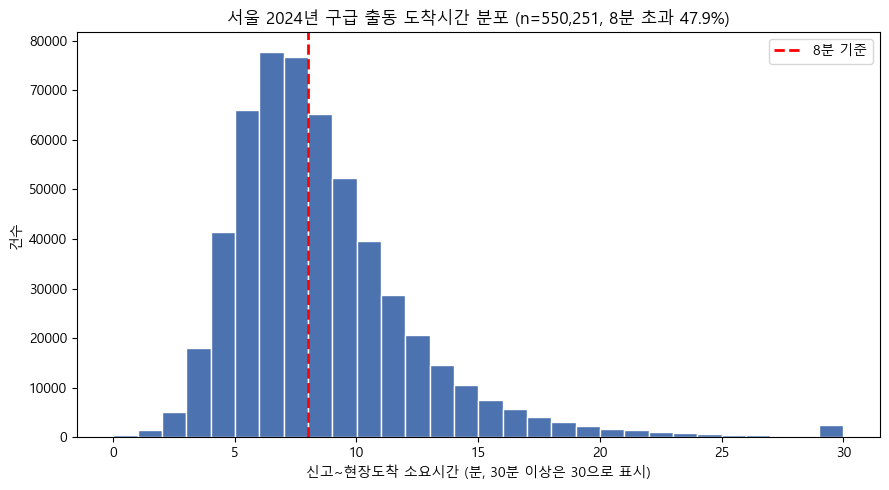

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(d["resp_min"].clip(upper=30), bins=30, color="#4C72B0", edgecolor="white")
ax.axvline(8, color="red", linestyle="--", linewidth=2, label="8분 기준")
ax.set_xlabel("신고~현장도착 소요시간 (분, 30분 이상은 30으로 표시)")
ax.set_ylabel("건수")
ax.set_title(f"서울 2024년 구급 출동 도착시간 분포 (n={len(d):,}, 8분 초과 {d['late'].mean()*100:.1f}%)")
ax.legend()
plt.tight_layout()
plt.savefig("eda/02_resp_dist.png", dpi=150)
plt.show()

### 7-1. 도착시각 분포

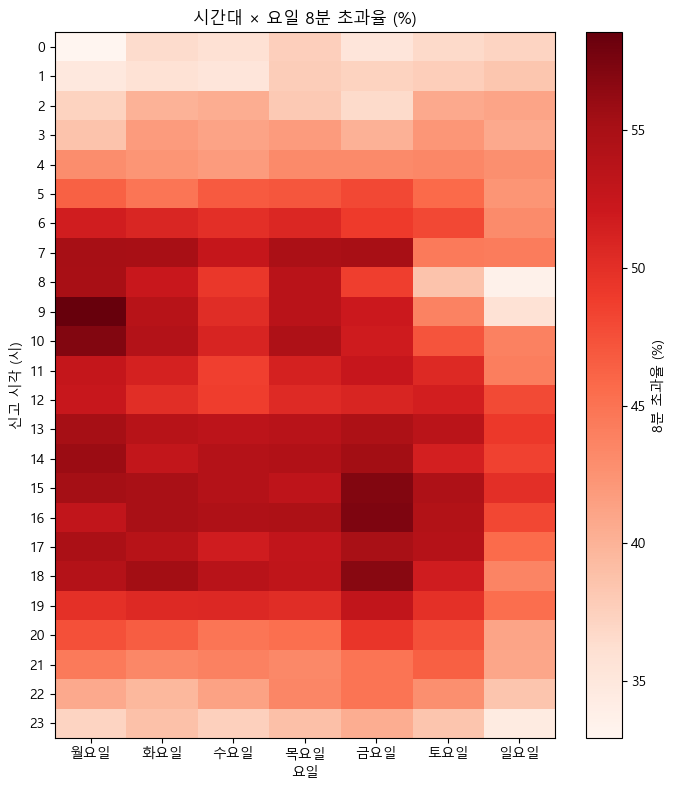

가장 높은 구간:
hour  dclr_dow
9     월요일         58.6
16    금요일         57.3
10    월요일         57.2
15    금요일         57.2
18    금요일         56.8
dtype: float64

가장 낮은 구간:
hour  dclr_dow
0     월요일         32.9
8     일요일         33.5
23    일요일         34.5
1     월요일         34.9
      수요일         35.3
dtype: float64


In [8]:
order = ["월요일", "화요일", "수요일", "목요일", "금요일", "토요일", "일요일"]
dows = [x for x in order if x in d["dclr_dow"].unique()]
if not dows:
    dows = sorted(d["dclr_dow"].dropna().unique())

p = d.pivot_table(values="late", index="hour", columns="dclr_dow", aggfunc="mean")
p = p[dows]

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(p.values * 100, aspect="auto", cmap="Reds")
ax.set_xticks(range(len(p.columns)), p.columns)
ax.set_yticks(range(len(p.index)), p.index)
ax.set_xlabel("요일")
ax.set_ylabel("신고 시각 (시)")
ax.set_title("시간대 × 요일 8분 초과율 (%)")
plt.colorbar(im, ax=ax, label="8분 초과율 (%)")
plt.tight_layout()
plt.savefig("eda/03_hour_dow.png", dpi=150)
plt.show()

print("가장 높은 구간:")
print((p * 100).round(1).stack().sort_values(ascending=False).head(5))
print("\n가장 낮은 구간:")
print((p * 100).round(1).stack().sort_values().head(5))

### 7-2.시간대 X 요일

분석 대상 센터 수: 144
초과율 범위: 23.0% ~ 74.1%


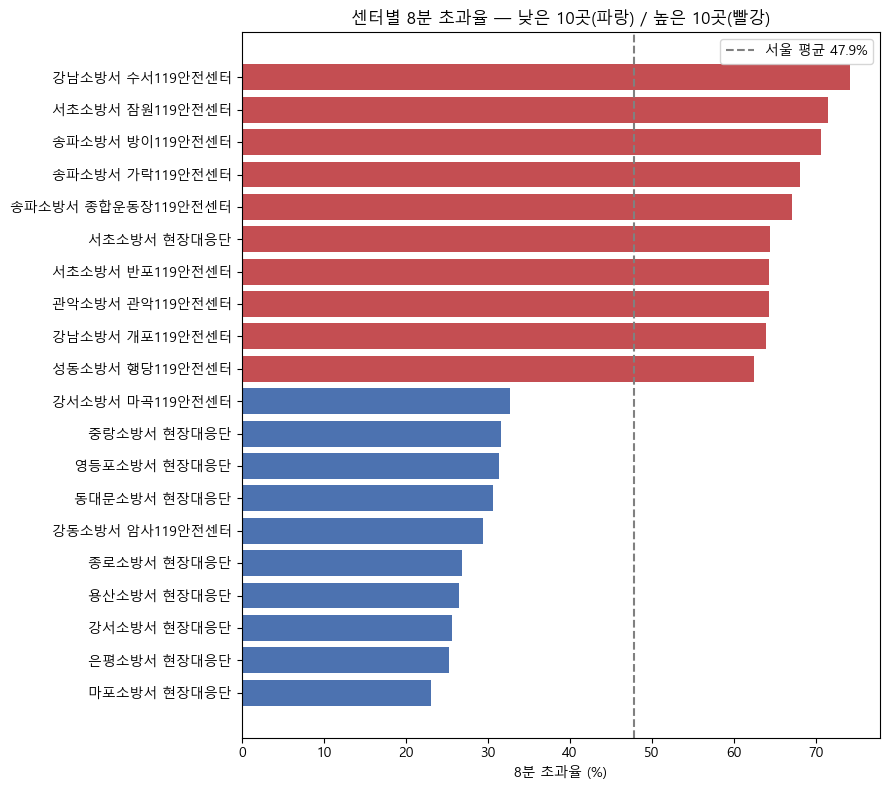

In [9]:
# 센터별 초과율 (건수 적은 센터는 제외)
g = d.groupby("center_id")["late"].agg(["mean", "count"])
g = g[g["count"] >= 300].sort_values("mean")

print("분석 대상 센터 수:", len(g))
print("초과율 범위: %.1f%% ~ %.1f%%" % (g["mean"].min()*100, g["mean"].max()*100))

# 상·하위 10개씩
show = pd.concat([g.head(10), g.tail(10)])
colors = ["#4C72B0"]*10 + ["#C44E52"]*10

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(range(len(show)), show["mean"]*100, color=colors)
ax.set_yticks(range(len(show)), show.index)
ax.axvline(d["late"].mean()*100, color="gray", linestyle="--", label="서울 평균 47.9%")
ax.set_xlabel("8분 초과율 (%)")
ax.set_title("센터별 8분 초과율 — 낮은 10곳(파랑) / 높은 10곳(빨강)")
ax.legend()
plt.tight_layout()
plt.savefig("eda/04_center.png", dpi=150)
plt.show()

### 7-3.센터별

In [10]:
d["unit_type"] = "center"
d.loc[d["cntr_nm"].str.contains("현장대응단", na=False), "unit_type"] = "field_unit"
d.loc[d["cntr_nm"].str.contains("구조", na=False), "unit_type"] = "rescue"

print(d.groupby("unit_type")["late"].agg(["mean", "count"]).assign(
    비율=lambda x: (x["mean"]*100).round(1)))

                mean   count    비율
unit_type                         
center      0.482638  528943  48.3
field_unit  0.384457   21308  38.4


안전센터 수: 119
초과율 범위: 29.4% ~ 74.1%


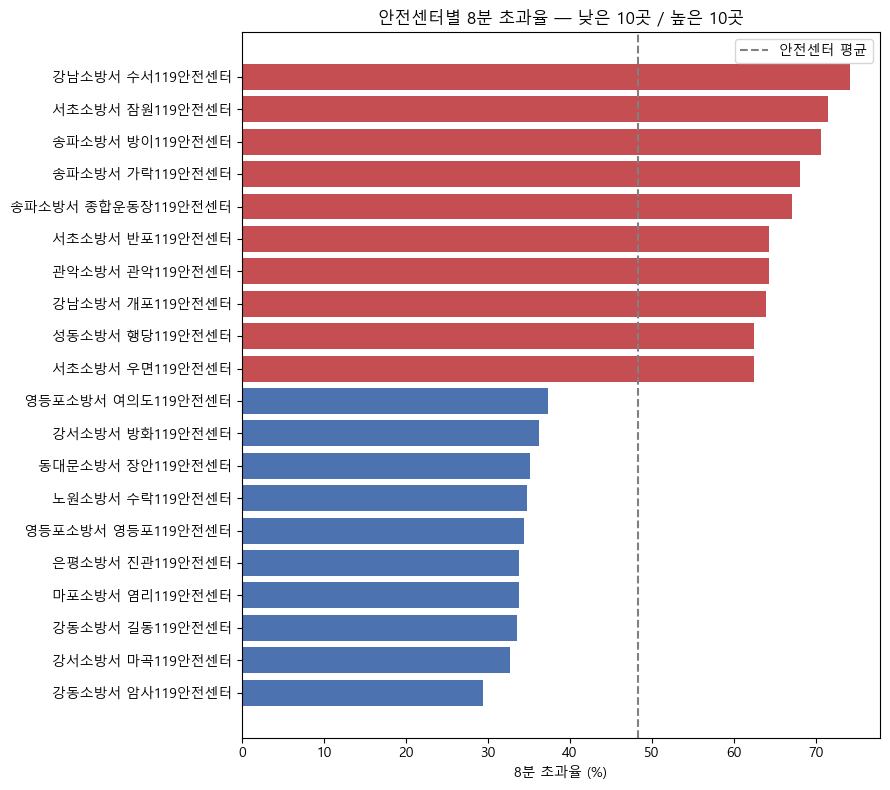

In [11]:
c = d[d["unit_type"] == "center"]
g2 = c.groupby("center_id")["late"].agg(["mean", "count"])
g2 = g2[g2["count"] >= 300].sort_values("mean")

print("안전센터 수:", len(g2))
print("초과율 범위: %.1f%% ~ %.1f%%" % (g2["mean"].min()*100, g2["mean"].max()*100))

show = pd.concat([g2.head(10), g2.tail(10)])
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(range(len(show)), show["mean"]*100, color=["#4C72B0"]*10 + ["#C44E52"]*10)
ax.set_yticks(range(len(show)), show.index)
ax.axvline(c["late"].mean()*100, color="gray", linestyle="--", label="안전센터 평균")
ax.set_xlabel("8분 초과율 (%)")
ax.set_title("안전센터별 8분 초과율 — 낮은 10곳 / 높은 10곳")
ax.legend()
plt.tight_layout()
plt.savefig("eda/04_center_only.png", dpi=150)
plt.show()

In [14]:
raw = pd.read_csv("work/seoul_2024_raw.csv", dtype=str, low_memory=False)
raw["center_id"] = raw["frstn_nm"].str.strip() + " " + raw["cntr_nm"].str.strip()

def mk(dcol, tcol, src):
    dd = src[dcol].astype(str).str.strip()
    tt = src[tcol].astype(str).str.strip().str.zfill(6)
    return pd.to_datetime(dd + tt, format="%Y%m%d%H%M%S", errors="coerce")

raw["dclr"] = mk("dclr_ymd", "dclr_tm", raw)
raw["dspt"] = mk("dspt_ymd", "dspt_tm", raw)

ev = (raw.dropna(subset=["dspt"])[["center_id", "dspt"]]
         .sort_values("dspt").reset_index(drop=True))
ev["one"] = 1

# 센터별로 하나씩 계산해서 이어 붙이기
parts = []
for cid, g in ev.groupby("center_id", sort=False):
    g = g.sort_values("dspt").copy()
    g["load60"] = (g.set_index("dspt")["one"]
                    .rolling("60min", closed="left").sum()
                    .fillna(0).values)
    parts.append(g)

ev = pd.concat(parts, ignore_index=True)
print(ev[["center_id", "dspt", "load60"]].head())
print("\n활동량 분포:")
print(ev["load60"].value_counts().sort_index().head(8))

         center_id                dspt  load60
0  노원소방서 상계119안전센터 2002-12-31 04:09:00     0.0
1  노원소방서 상계119안전센터 2024-01-01 00:14:00     0.0
2  노원소방서 상계119안전센터 2024-01-01 00:14:00     0.0
3  노원소방서 상계119안전센터 2024-01-01 00:14:00     0.0
4  노원소방서 상계119안전센터 2024-01-01 00:14:00     0.0

활동량 분포:
load60
0.0    359031
1.0    157454
2.0     55311
3.0      6501
4.0      4812
5.0       104
6.0       611
7.0         8
Name: count, dtype: int64


In [15]:
d2 = d.copy()
d2["dclr"] = pd.to_datetime(d2["dclr"])
d2 = d2.sort_values("dclr").reset_index(drop=True)

merged = pd.merge_asof(
    d2, ev[["center_id", "dspt", "load60"]].sort_values("dspt"),
    left_on="dclr", right_on="dspt", by="center_id",
    direction="backward", tolerance=pd.Timedelta("60min"))
merged["load60"] = merged["load60"].fillna(0)

print("전체:", len(merged))
print(merged["load60"].describe())

전체: 550251
count    550251.000000
mean          0.257719
std           0.636952
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          10.000000
Name: load60, dtype: float64


In [19]:
raw = pd.read_csv("work/seoul_2024_raw.csv", dtype=str, low_memory=False)
raw["center_id"] = raw["frstn_nm"].str.strip() + " " + raw["cntr_nm"].str.strip()

def mk(dcol, tcol, src):
    dd = src[dcol].astype(str).str.strip()
    tt = src[tcol].astype(str).str.strip().str.zfill(6)
    return pd.to_datetime(dd + tt, format="%Y%m%d%H%M%S", errors="coerce")

raw["dclr"] = mk("dclr_ymd", "dclr_tm", raw)
raw["dspt"] = mk("dspt_ymd", "dspt_tm", raw)

ev = (raw.dropna(subset=["dspt"])[["center_id", "dspt"]]
         .sort_values("dspt").reset_index(drop=True))
ev["one"] = 1

# 센터별로 하나씩 계산해서 이어 붙이기
parts = []
for cid, g in ev.groupby("center_id", sort=False):
    g = g.sort_values("dspt").copy()
    g["load60"] = (g.set_index("dspt")["one"]
                    .rolling("60min", closed="left").sum()
                    .fillna(0).values)
    parts.append(g)

ev = pd.concat(parts, ignore_index=True)
print(ev[["center_id", "dspt", "load60"]].head())
print("\n활동량 분포:")
print(ev["load60"].value_counts().sort_index().head(8))

         center_id                dspt  load60
0  노원소방서 상계119안전센터 2002-12-31 04:09:00     0.0
1  노원소방서 상계119안전센터 2024-01-01 00:14:00     0.0
2  노원소방서 상계119안전센터 2024-01-01 00:14:00     0.0
3  노원소방서 상계119안전센터 2024-01-01 00:14:00     0.0
4  노원소방서 상계119안전센터 2024-01-01 00:14:00     0.0

활동량 분포:
load60
0.0    359031
1.0    157454
2.0     55311
3.0      6501
4.0      4812
5.0       104
6.0       611
7.0         8
Name: count, dtype: int64


In [17]:
print("2024년 외 기록:", (ev["dspt"].dt.year != 2024).sum())
print(ev.loc[ev["dspt"].dt.year != 2024, "dspt"].dt.year.value_counts())

# 같은 센터·같은 시각 중복
dup = ev.groupby(["center_id", "dspt"]).size()
print("\n같은 센터·같은 시각 2건 이상:", (dup > 1).sum(), "쌍")
print(dup.value_counts().head())

2024년 외 기록: 18
dspt
2202    6
2025    5
2021    3
2022    2
2002    1
2102    1
Name: count, dtype: int64

같은 센터·같은 시각 2건 이상: 30162 쌍
1    522808
2     29720
4       290
3       135
5        10
Name: count, dtype: int64


In [18]:
ev = ev[ev["dspt"].dt.year == 2024].copy()   # 연도 오류 제거

parts = []
for cid, g in ev.groupby("center_id", sort=False):
    g = g.sort_values("dspt").copy()
    g["load60"] = (g.set_index("dspt")["one"]
                    .rolling("60min", closed="left").sum()
                    .fillna(0).values)
    parts.append(g)
ev = pd.concat(parts, ignore_index=True)

print(ev["load60"].value_counts().sort_index().head(8))

load60
0.0    359014
1.0    157453
2.0     55311
3.0      6501
4.0      4812
5.0       104
6.0       611
7.0         8
Name: count, dtype: int64


In [20]:
# 6건인 기록들이 어느 센터·언제인지
six = ev[ev["load60"] >= 6]
print("센터별:", six["center_id"].value_counts().head())
print("\n시각 예시:")
print(six[["center_id", "dspt"]].head(10))

# 같은 센터·같은 시각 중복 확인
dup = ev.groupby(["center_id", "dspt"]).size()
print("\n중복 쌍 수:", (dup > 1).sum())
print(dup.value_counts().head())

센터별: center_id
금천소방서 현장대응단        102
은평소방서 현장대응단         42
영등포소방서 현장대응단        36
노원소방서 상계119안전센터     35
도봉소방서 현장대응단         34
Name: count, dtype: int64

시각 예시:
           center_id                dspt
19   노원소방서 상계119안전센터 2024-01-01 06:02:00
20   노원소방서 상계119안전센터 2024-01-01 06:02:00
164  노원소방서 상계119안전센터 2024-01-04 12:46:00
165  노원소방서 상계119안전센터 2024-01-04 12:46:00
176  노원소방서 상계119안전센터 2024-01-04 15:51:00
177  노원소방서 상계119안전센터 2024-01-04 15:51:00
178  노원소방서 상계119안전센터 2024-01-04 16:03:00
179  노원소방서 상계119안전센터 2024-01-04 16:03:00
232  노원소방서 상계119안전센터 2024-01-05 19:59:00
233  노원소방서 상계119안전센터 2024-01-05 19:59:00

중복 쌍 수: 30162
1    522808
2     29720
4       290
3       135
5        10
Name: count, dtype: int64


In [21]:
d2 = d.copy()
d2["dclr"] = pd.to_datetime(d2["dclr"])
d2 = d2.sort_values("dclr").reset_index(drop=True)

merged = pd.merge_asof(
    d2, ev[["center_id", "dspt", "load60"]].sort_values("dspt"),
    left_on="dclr", right_on="dspt", by="center_id",
    direction="backward", tolerance=pd.Timedelta("60min"))
merged["load60"] = merged["load60"].fillna(0)

print("건수:", len(merged))
print(merged["load60"].value_counts().sort_index().head(8))

건수: 550251
load60
0.0    451824
1.0     65288
2.0     26724
3.0      3473
4.0      2517
5.0        58
6.0       328
7.0         6
Name: count, dtype: int64


        비율(%)   count
load60               
0.0      47.6  451824
1.0      49.8   65288
2.0      47.7   26724
3.0      48.7    3473
4.0      43.4    2942


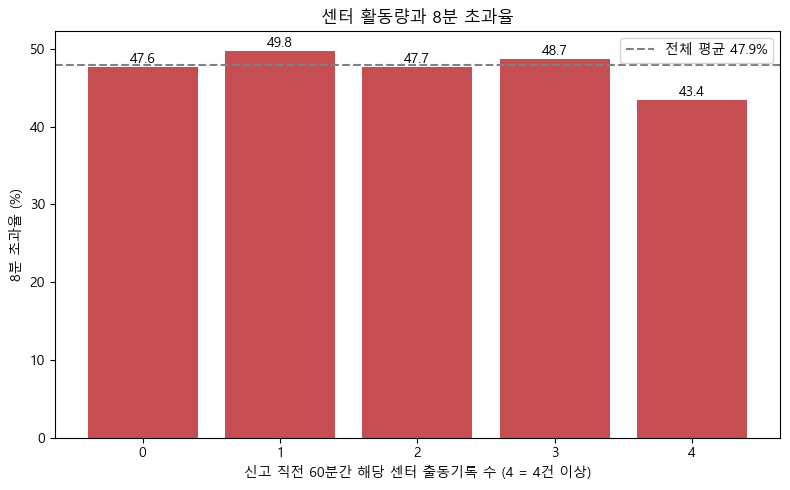

In [22]:
r = merged.groupby(merged["load60"].clip(upper=4))["late"].agg(["mean", "count"])
r["비율(%)"] = (r["mean"] * 100).round(1)
print(r[["비율(%)", "count"]])

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(r.index.astype(int), r["mean"] * 100, color="#C44E52")
ax.axhline(d["late"].mean() * 100, color="gray", linestyle="--", label="전체 평균 47.9%")
ax.set_xlabel("신고 직전 60분간 해당 센터 출동기록 수 (4 = 4건 이상)")
ax.set_ylabel("8분 초과율 (%)")
ax.set_title("센터 활동량과 8분 초과율")
for b, v in zip(bars, r["mean"] * 100):
    ax.text(b.get_x() + b.get_width()/2, v + 0.5, f"{v:.1f}", ha="center")
ax.legend()
plt.tight_layout()
plt.savefig("eda/05_load.png", dpi=150)
plt.show()

In [23]:
# 낮 시간대(9~18시)만 떼어서 보기
day = merged[merged["hour"].between(9, 18)]
r2 = day.groupby(day["load60"].clip(upper=3))["late"].agg(["mean", "count"])
print("낮 시간대(9~18시):")
print((r2["mean"]*100).round(1))
print(r2["count"])

# 새벽(0~5시)
night = merged[merged["hour"].between(0, 5)]
r3 = night.groupby(night["load60"].clip(upper=3))["late"].agg(["mean", "count"])
print("\n새벽(0~5시):")
print((r3["mean"]*100).round(1))
print(r3["count"])

낮 시간대(9~18시):
load60
0.0    51.8
1.0    54.5
2.0    52.8
3.0    52.0
Name: mean, dtype: float64
load60
0.0    213606
1.0     34372
2.0     14286
3.0      3415
Name: count, dtype: int64

새벽(0~5시):
load60
0.0    40.1
1.0    38.2
2.0    36.3
3.0    33.9
Name: mean, dtype: float64
load60
0.0    81464
1.0     8508
2.0     3387
3.0      846
Name: count, dtype: int64


In [24]:
# 구별 직전 60분 신고 건수
raw2 = raw.dropna(subset=["dclr"]).sort_values("dclr").reset_index(drop=True)
raw2["one"] = 1

parts = []
for gu, g in raw2.groupby("sgg_nm", sort=False):
    g = g.sort_values("dclr").copy()
    g["sgg_load"] = (g.set_index("dclr")["one"]
                      .rolling("60min", closed="left").sum().fillna(0).values)
    parts.append(g[["sgg_nm", "dclr", "sgg_load"]])
gu_ev = pd.concat(parts, ignore_index=True).sort_values("dclr")

m2 = pd.merge_asof(merged.sort_values("dclr"), gu_ev,
                   on="dclr", by="sgg_nm", direction="backward",
                   tolerance=pd.Timedelta("60min"))
m2["sgg_load"] = m2["sgg_load"].fillna(0)

q = pd.qcut(m2["sgg_load"], 5, labels=["매우 낮음","낮음","보통","높음","매우 높음"])
print(m2.groupby(q)["late"].agg(["mean","count"]).assign(
    비율=lambda x: (x["mean"]*100).round(1))[["비율","count"]])

            비율   count
sgg_load              
매우 낮음     41.5  148445
낮음        44.9  111198
보통        48.3   92544
높음        52.0  120461
매우 높음     57.4   77603


C:\Users\DongHyeok\AppData\Local\Temp\ipykernel_15932\3761893280.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(m2.groupby(q)["late"].agg(["mean","count"]).assign(


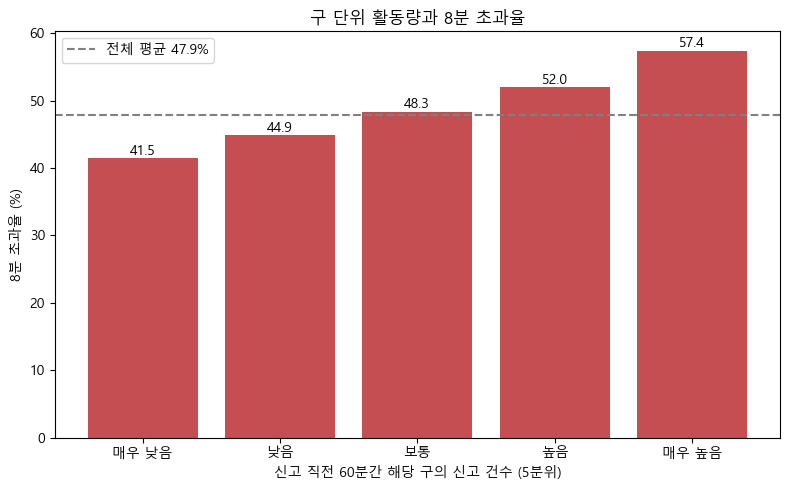

In [25]:
q = pd.qcut(m2["sgg_load"], 5, labels=["매우 낮음","낮음","보통","높음","매우 높음"])
rg = m2.groupby(q, observed=True)["late"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(range(len(rg)), rg["mean"] * 100, color="#C44E52")
ax.axhline(d["late"].mean() * 100, color="gray", linestyle="--", label="전체 평균 47.9%")
ax.set_xticks(range(len(rg)), rg.index)
ax.set_xlabel("신고 직전 60분간 해당 구의 신고 건수 (5분위)")
ax.set_ylabel("8분 초과율 (%)")
ax.set_title("구 단위 활동량과 8분 초과율")
for b, v in zip(bars, rg["mean"] * 100):
    ax.text(b.get_x() + b.get_width()/2, v + 0.5, f"{v:.1f}", ha="center")
ax.legend()
plt.tight_layout()
plt.savefig("eda/06_sgg_load.png", dpi=150)
plt.show()

In [12]:
import pandas as pd, glob

cols = ["ctpv_nm", "dclr_ymd", "dclr_tm", "grnds_arvl_ymd", "grnds_arvl_tm", "trmn_se_nm"]

for f in sorted(glob.glob("raw/*.csv")):
    h = pd.read_csv(f, nrows=1, dtype=str, encoding="utf-8")
    name = f.split("\\")[-1]
    missing = [c for c in cols if c not in h.columns]
    print(name, "| 컬럼", len(h.columns), "| 없는 것:", missing)

구급 현황_2019_전국.csv | 컬럼 71 | 없는 것: ['ctpv_nm', 'dclr_ymd', 'dclr_tm', 'grnds_arvl_ymd', 'grnds_arvl_tm', 'trmn_se_nm']
구급 현황_2020_전국.csv | 컬럼 71 | 없는 것: ['ctpv_nm', 'dclr_ymd', 'dclr_tm', 'grnds_arvl_ymd', 'grnds_arvl_tm', 'trmn_se_nm']
구급 현황_2021_전국.csv | 컬럼 71 | 없는 것: ['ctpv_nm', 'dclr_ymd', 'dclr_tm', 'grnds_arvl_ymd', 'grnds_arvl_tm', 'trmn_se_nm']
구급 현황_2022_전국.csv | 컬럼 71 | 없는 것: ['ctpv_nm', 'dclr_ymd', 'dclr_tm', 'grnds_arvl_ymd', 'grnds_arvl_tm', 'trmn_se_nm']
구급 현황_2023_전국.csv | 컬럼 71 | 없는 것: ['ctpv_nm', 'dclr_ymd', 'dclr_tm', 'grnds_arvl_ymd', 'grnds_arvl_tm', 'trmn_se_nm']
구급 현황_2024_전국.csv | 컬럼 71 | 없는 것: []
구급 현황_2025_전국.csv | 컬럼 71 | 없는 것: []


In [13]:
h19 = pd.read_csv("raw/구급 현황_2019_전국.csv", nrows=2, dtype=str, encoding="utf-8")
h24 = pd.read_csv("raw/구급 현황_2024_전국.csv", nrows=2, dtype=str, encoding="utf-8")

print("=== 2019 ===")
for i, c in enumerate(h19.columns):
    print(i, c)

=== 2019 ===
0 RLF_RPTP_NO
1 REG_CMPTN_SE_NM
2 PTN_OCRN_TYPE_NM
3 PTN_SYM_SE_NM
4 SRIL_ONCR_NM
5 HRTARST_NM
6 CRDVSC_CRVSSCR_SE_NM
7 TRFC_ACDNT_SE_NM
8 ETC_TRFC_ACDNT_NM
9 ANML_ETC_CLSF_NM
10 ETC_OCRN_TYPE_NM
11 FRSTN_NM
12 CNTR_NM
13 RLF_ACTV_SE_NM
14 HLCPT_PMPBLC_EN_NM
15 DCLR_YMD
16 DCLR_TM
17 DCLR_YR
18 SEASN_NM
19 QTR_NO
20 DCLR_MM
21 DCLR_DAY
22 DCLR_HR
23 DCLR_MN
24 DCLR_DOW
25 DSPT_YMD
26 DSPT_TM
27 DSPT_YR
28 DSPT_MM
29 DSPT_DAY
30 DSPT_HR
31 DSPT_MN
32 GRNDS_ARVL_YMD
33 GRNDS_ARVL_TM
34 GRNDS_ARVL_YR
35 GRNDS_ARVL_MM
36 GRNDS_ARVL_DAY
37 GRNDS_ARVL_HR
38 GRNDS_ARVL_MN
39 PTN_CNTC_YMD
40 PTN_CNTC_TM
41 PTN_CNTC_YR
42 PTN_CNTC_MM
43 PTN_CNTC_DAY
44 PTN_CNTC_HR
45 PTN_CNTC_MN
46 GRNDS_DSTNC
47 GRNDS_DPTRE_YMD
48 GRNDS_DPTRE_TM
49 GRNDS_DPTRE_YR
50 GRNDS_DPTRE_MM
51 GRNDS_DPTRE_DAY
52 GRNDS_DPTRE_HR
53 GRNDS_DPTRE_MN
54 CBK_YMD
55 CBK_TM
56 CBK_YR
57 CBK_MM
58 CBK_DAY
59 CBK_HR
60 CBK_MN
61 TRMN_SE_NM
62 GNDR_NM
63 PTN_CTPV_NM
64 CTPV_NM
65 SGG_NM
66 CTY_FRMVL_SE_NM
67 PTN_CR_NM


In [14]:
import re

NA = ["\\N", "\\\\N", ""]
cols = ["ctpv_nm", "dclr_ymd", "dclr_tm", "grnds_arvl_ymd", "grnds_arvl_tm", "trmn_se_nm"]

rows = []
for f in sorted(glob.glob("raw/*.csv")):
    year = re.search(r"(20\d{2})", f).group(1)
    parts = []
    for c in pd.read_csv(f, dtype=str, na_values=NA, chunksize=500_000,
                         encoding="utf-8", low_memory=False):
        c.columns = c.columns.str.lower()          # ← 소문자 통일
        c = c[cols]
        parts.append(c[c["ctpv_nm"] == "서울특별시"])
    s = pd.concat(parts, ignore_index=True)

    for col in s.columns:
        s[col] = s[col].astype(str).str.strip().replace({"": None, "nan": None, "\\N": None})

    dc = pd.to_datetime(s["dclr_ymd"] + s["dclr_tm"].str.zfill(6),
                        format="%Y%m%d%H%M%S", errors="coerce")
    ar = pd.to_datetime(s["grnds_arvl_ymd"] + s["grnds_arvl_tm"].str.zfill(6),
                        format="%Y%m%d%H%M%S", errors="coerce")
    rm = (ar - dc).dt.total_seconds() / 60

    keep = (~s["trmn_se_nm"].astype(str).str.contains("취소", na=False)) & \
           rm.notna() & (rm > 0) & (rm <= 180)
    rm = rm[keep]

    rows.append({"연도": year, "서울 원본": len(s), "분석 대상": len(rm),
                 "평균(분)": round(rm.mean(), 2),
                 "중앙값(분)": round(rm.median(), 2),
                 "8분 초과율(%)": round((rm > 8).mean() * 100, 1)})
    print(rows[-1])

yr = pd.DataFrame(rows)
yr.to_csv("eda/yearly.csv", index=False, encoding="utf-8-sig")
yr

{'연도': '2019', '서울 원본': 264620, '분석 대상': 243583, '평균(분)': np.float64(7.13), '중앙값(분)': np.float64(6.0), '8분 초과율(%)': np.float64(21.2)}
{'연도': '2020', '서울 원본': 478562, '분석 대상': 439466, '평균(분)': np.float64(9.02), '중앙값(분)': np.float64(8.0), '8분 초과율(%)': np.float64(37.7)}
{'연도': '2021', '서울 원본': 551195, '분석 대상': 499041, '평균(분)': np.float64(10.62), '중앙값(분)': np.float64(8.0), '8분 초과율(%)': np.float64(47.2)}
{'연도': '2022', '서울 원본': 574577, '분석 대상': 524856, '평균(분)': np.float64(10.01), '중앙값(분)': np.float64(9.0), '8분 초과율(%)': np.float64(50.8)}
{'연도': '2023', '서울 원본': 610978, '분석 대상': 569863, '평균(분)': np.float64(8.8), '중앙값(분)': np.float64(8.0), '8분 초과율(%)': np.float64(42.5)}
{'연도': '2024', '서울 원본': 585503, '분석 대상': 550251, '평균(분)': np.float64(8.79), '중앙값(분)': np.float64(8.0), '8분 초과율(%)': np.float64(47.9)}
{'연도': '2025', '서울 원본': 548305, '분석 대상': 518030, '평균(분)': np.float64(9.05), '중앙값(분)': np.float64(8.15), '8분 초과율(%)': np.float64(51.8)}


,연도,서울 원본,분석 대상,평균(분),중앙값(분),8분 초과율(%)
0,2019,264620,243583,7.13,6.00,21.2
1,2020,478562,439466,9.02,8.00,37.7
2,2021,551195,499041,10.62,8.00,47.2
3,2022,574577,524856,10.01,9.00,50.8
4,2023,610978,569863,8.80,8.00,42.5
5,2024,585503,550251,8.79,8.00,47.9
6,2025,548305,518030,9.05,8.15,51.8


In [15]:
s19 = pd.read_csv("raw/구급 현황_2019_전국.csv", dtype=str, encoding="utf-8",
                  usecols=lambda c: c.lower() in ["ctpv_nm", "dclr_ymd"])
s19.columns = s19.columns.str.lower()
s19 = s19[s19["ctpv_nm"] == "서울특별시"]
print("월별 건수:")
print(s19["dclr_ymd"].str[:6].value_counts().sort_index())

월별 건수:
dclr_ymd
201901    21288
201902    18670
201903    21047
201904    21504
201905    23197
201906    21843
201907    24038
201908    23982
201909    22496
201910    22792
201911    21481
201912    22282
Name: count, dtype: int64


In [17]:
def peek(path, cols):
    s = pd.read_csv(path, dtype=str, encoding="utf-8",
                    usecols=lambda c: c.lower() in cols)
    s.columns = s.columns.str.lower()
    return s[s["ctpv_nm"] == "서울특별시"]

cols = ["ctpv_nm", "trmn_se_nm", "rlf_actv_se_nm", "trans_clsf_nm", "cntr_nm"]
a = peek("raw/구급 현황_2019_전국.csv", cols)
b = peek("raw/구급 현황_2024_전국.csv", cols)

for c in ["trmn_se_nm", "rlf_actv_se_nm", "trans_clsf_nm"]:
    print(f"\n=== {c} ===")
    print(pd.DataFrame({
        "2019": a[c].value_counts(normalize=True).mul(100).round(1),
        "2024": b[c].value_counts(normalize=True).mul(100).round(1)
    }))

print("\n2019 센터 수:", a["cntr_nm"].nunique(), "| 2024 센터 수:", b["cntr_nm"].nunique())


=== trmn_se_nm ===
            2019  2024
trmn_se_nm            
거짓           0.0   NaN
구급오인         0.4   0.4
기타           2.4   0.2
정상          93.5  97.7
취소           3.8   1.7
허위           NaN   0.0

=== rlf_actv_se_nm ===
                2019  2024
rlf_actv_se_nm            
특수일반            79.9  92.9
특수전문            20.1   7.1

=== trans_clsf_nm ===
               2019  2024
trans_clsf_nm            
이송             64.1  51.5
미이송            28.0  40.9
소방활동            5.8   5.6
연계이송            2.1   1.9

2019 센터 수: 109 | 2024 센터 수: 165


In [18]:
only24 = set(b["cntr_nm"].unique()) - set(a["cntr_nm"].unique())
print("2024에만 있는 조직:", len(only24))
print(sorted(only24)[:20])

2024에만 있는 조직: 64
['119항공대', '가산119안전센터', '강일119안전센터', '격포119안전센터', '경포119안전센터', '고등119안전센터', '고봉119안전센터', '고일119안전센터', '공흥119안전센터', '관악119안전센터', '광영119안전센터', '괴산119안전센터', '괴안119안전센터', '구의119안전센터', '금천119안전센터', '대부119안전센터', '동작119안전센터', '둔내119안전센터', '등촌119안전센터', '마천119안전센터']


In [19]:
cols = ["ctpv_nm", "frstn_nm", "cntr_nm"]
a = peek("raw/구급 현황_2019_전국.csv", cols)
b = peek("raw/구급 현황_2024_전국.csv", cols)

for x in (a, b):
    x["center_id"] = x["frstn_nm"].str.strip() + " " + x["cntr_nm"].str.strip()

print("2019 서울 조직 수:", a["center_id"].nunique())
print("2024 서울 조직 수:", b["center_id"].nunique())

only24 = sorted(set(b["center_id"]) - set(a["center_id"]))
only19 = sorted(set(a["center_id"]) - set(b["center_id"]))
print("\n2024에만:", len(only24))
print(only24[:15])
print("\n2019에만:", len(only19))
print(only19[:15])

# 소방서 수도 비교
print("\n2019 소방서:", a["frstn_nm"].nunique(), "| 2024 소방서:", b["frstn_nm"].nunique())

2019 서울 조직 수: 136
2024 서울 조직 수: 189

2024에만: 66
['119특수구조단 119항공대', '강남소방서 삼성119안전센터', '강동소방서 강일119안전센터', '강동소방서 성내119안전센터', '강릉소방서 경포119안전센터', '강북소방서 번동119안전센터', '강북소방서 부계119지역대', '강서소방서 등촌119안전센터', '거제소방서 옥포119안전센터', '거창소방서 위천119안전센터', '검단소방서 오류119안전센터', '계양소방서 장기119안전센터', '고양소방서 삼송119안전센터', '고양소방서 화전119안전센터', '관악소방서 관악119안전센터']

2019에만: 13
['119특수구조단 소방항공대', '강북소방서 재난관리과', '강서소방서 재난관리과', '관악소방서 재난관리과', '구로소방서 독산119안전센터', '구로소방서 시흥119안전센터', '김포소방서 고촌119안전센터', '도봉소방서 재난관리과', '분당소방서 구미119안전센터', '송파소방서 예방과', '은평소방서 재난관리과', '하남소방서 감북119안전센터', '해남소방서 진도119안전센터']

2019 소방서: 34 | 2024 소방서: 58


In [20]:
print("=== 2024 서울 신고의 출동 소방서 상위 30 ===")
print(b["frstn_nm"].value_counts().head(30))
print("\n=== 하위(드문) 20 ===")
print(b["frstn_nm"].value_counts().tail(20))

=== 2024 서울 신고의 출동 소방서 상위 30 ===
frstn_nm
강남소방서       34598
송파소방서       30581
마포소방서       29137
구로소방서       29121
서초소방서       28479
영등포소방서      28213
강서소방서       27322
노원소방서       27287
관악소방서       27139
강동소방서       25975
양천소방서       25155
은평소방서       24402
강북소방서       23909
중랑소방서       23343
동대문소방서      23123
성북소방서       21267
서대문소방서      20203
도봉소방서       18762
광진소방서       18280
중부소방서       18114
종로소방서       18045
동작소방서       17482
용산소방서       16207
성동소방서       15608
금천소방서       13494
119특수구조단      183
재난대응과          15
광명소방서          11
성남소방서           7
부천소방서           5
Name: count, dtype: int64

=== 하위(드문) 20 ===
frstn_nm
하남소방서     1
김포소방서     1
임실소방서     1
칠곡소방서     1
홍천소방서     1
부안소방서     1
성주소방서     1
남양주소방서    1
포천소방서     1
강릉소방서     1
횡성소방서     1
괴산소방서     1
일산소방서     1
양양소방서     1
의정부소방서    1
거창소방서     1
양평소방서     1
안양소방서     1
검단소방서     1
거제소방서     1
Name: count, dtype: int64


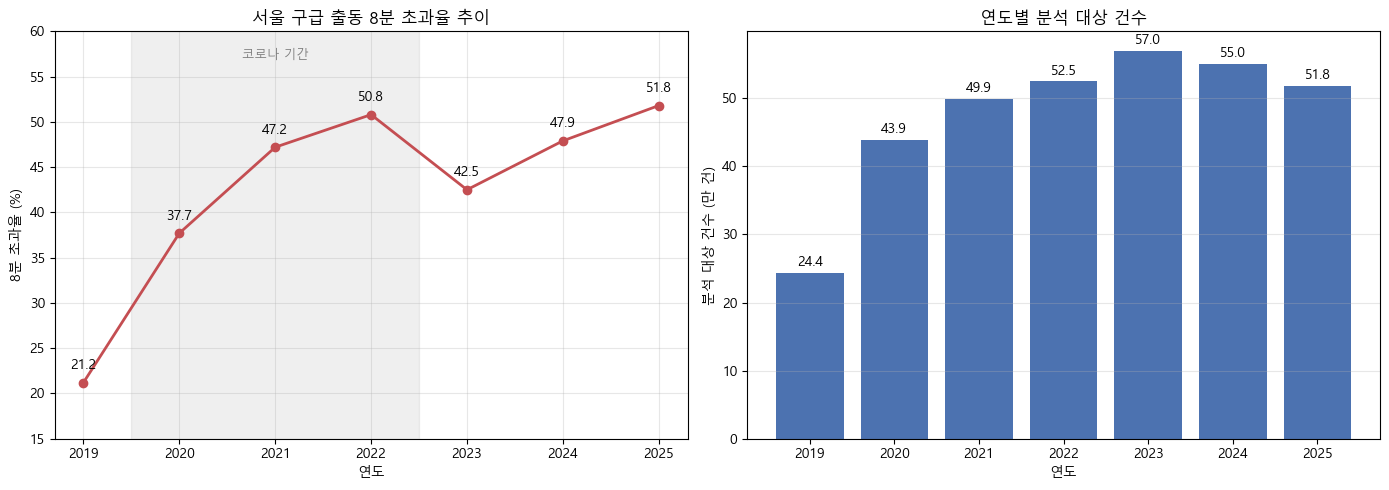

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 왼쪽: 8분 초과율 추이
ax1.plot(yr["연도"], yr["8분 초과율(%)"], marker="o", linewidth=2, color="#C44E52")
for x, v in zip(yr["연도"], yr["8분 초과율(%)"]):
    ax1.text(x, v + 1.5, f"{v}", ha="center", fontsize=10)
ax1.set_ylabel("8분 초과율 (%)")
ax1.set_xlabel("연도")
ax1.set_title("서울 구급 출동 8분 초과율 추이")
ax1.set_ylim(15, 60)
ax1.axvspan(0.5, 3.5, alpha=0.12, color="gray")   # 2020~2022 코로나 구간
ax1.text(2, 57, "코로나 기간", ha="center", fontsize=9, color="gray")
ax1.grid(alpha=0.3)

# 오른쪽: 분석 대상 건수
ax2.bar(yr["연도"], yr["분석 대상"] / 10000, color="#4C72B0")
for x, v in zip(yr["연도"], yr["분석 대상"] / 10000):
    ax2.text(x, v + 1, f"{v:.1f}", ha="center", fontsize=10)
ax2.set_ylabel("분석 대상 건수 (만 건)")
ax2.set_xlabel("연도")
ax2.set_title("연도별 분석 대상 건수")
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("eda/07_yearly.png", dpi=150)
plt.show()

In [22]:
cols = ["ctpv_nm", "dclr_ymd", "dclr_tm", "grnds_arvl_ymd", "grnds_arvl_tm", "trmn_se_nm"]

parts = []
for c in pd.read_csv("raw/구급 현황_2024_전국.csv", dtype=str, na_values=NA,
                     chunksize=500_000, encoding="utf-8", low_memory=False):
    c.columns = c.columns.str.lower()
    parts.append(c[cols])
nat = pd.concat(parts, ignore_index=True)

for col in nat.columns:
    nat[col] = nat[col].astype(str).str.strip().replace({"": None, "nan": None, "\\N": None})

dc = pd.to_datetime(nat["dclr_ymd"] + nat["dclr_tm"].str.zfill(6),
                    format="%Y%m%d%H%M%S", errors="coerce")
ar = pd.to_datetime(nat["grnds_arvl_ymd"] + nat["grnds_arvl_tm"].str.zfill(6),
                    format="%Y%m%d%H%M%S", errors="coerce")
nat["resp_min"] = (ar - dc).dt.total_seconds() / 60

keep = (~nat["trmn_se_nm"].astype(str).str.contains("취소", na=False)) & \
       nat["resp_min"].notna() & (nat["resp_min"] > 0) & (nat["resp_min"] <= 180)
nat = nat[keep]
nat["late"] = nat["resp_min"] > 8

g = nat.groupby("ctpv_nm")["late"].agg(["mean", "count"]).sort_values("mean")
g["초과율(%)"] = (g["mean"] * 100).round(1)
print("전국 평균: %.1f%%" % (nat["late"].mean() * 100))
print(g[["초과율(%)", "count"]])

전국 평균: 56.4%
         초과율(%)   count
ctpv_nm                
대구광역시      40.6  130020
광주광역시      45.6   69990
서울특별시      47.9  550251
인천광역시      49.9  168060
경상남도       51.9  180503
부산광역시      52.9  167769
울산광역시      54.9   46559
제주특별자치도    55.0   52619
세종특별자치시    55.8   15939
대전광역시      58.5   76820
경상북도       61.5  155363
경기도        62.7  679177
강원특별자치도    62.8  119098
전라남도       63.6  128506
충청남도       64.4  141742
전북특별자치도    65.2  127078
충청북도       67.3  100702


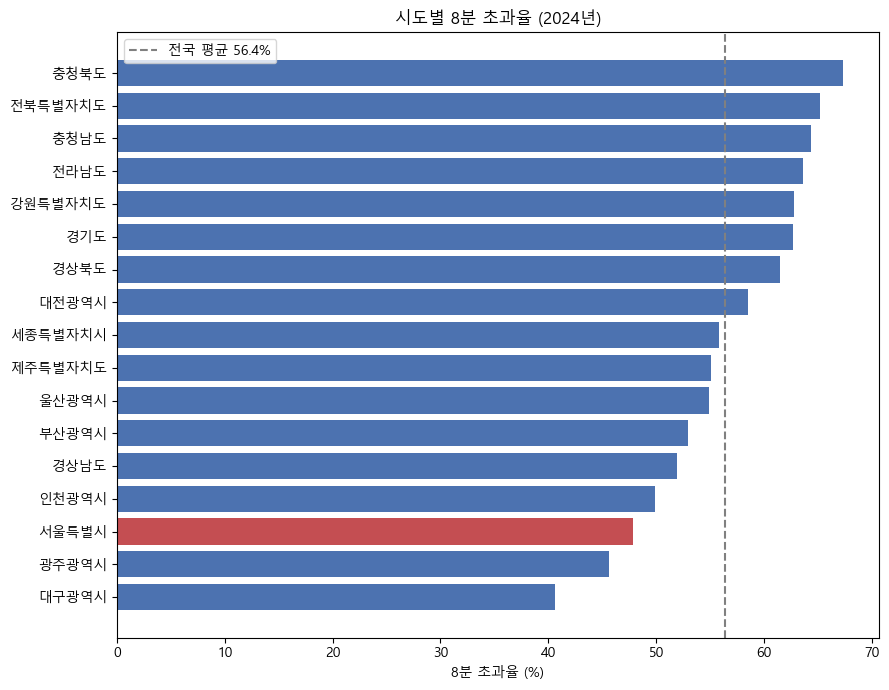

In [30]:
g2 = g.sort_values("mean")
colors = ["#C44E52" if i == "서울특별시" else "#4C72B0" for i in g2.index]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(range(len(g2)), g2["mean"] * 100, color=colors)
ax.set_yticks(range(len(g2)))
ax.set_yticklabels(g2.index)          # 라벨은 따로
ax.axvline(nat["late"].mean() * 100, color="gray", linestyle="--",
           label="전국 평균 56.4%")
ax.set_xlabel("8분 초과율 (%)")
ax.set_title("시도별 8분 초과율 (2024년)")
ax.legend()
plt.tight_layout()
plt.savefig("eda/08_sido.png", dpi=150)
plt.show()

In [29]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["font.family"] = "Malgun Gothic"
matplotlib.rcParams["axes.unicode_minus"] = False
print("준비 완료")

준비 완료


In [36]:
d = pd.read_csv("work/seoul_2024_clean.csv", low_memory=False)
d["late"] = d["resp_min"] > 8
d["dist_km"] = pd.to_numeric(d["grnds_dstnc"], errors="coerce")
print(len(d), "건 | 8분 초과", round(d["late"].mean()*100, 1), "%")

550251 건 | 8분 초과 47.9 %


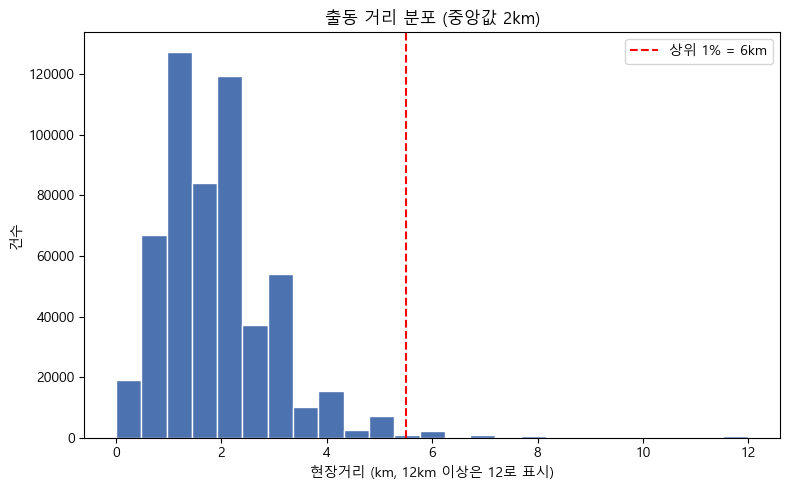

In [39]:
dk = d.loc[d["dist_km"] >= 0, "dist_km"]
p99 = dk.quantile(0.99)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(dk.clip(upper=12), bins=25, color="#4C72B0", edgecolor="white")
ax.axvline(p99, color="red", linestyle="--", label=f"상위 1% = {p99:.0f}km")
ax.set_xlabel("현장거리 (km, 12km 이상은 12로 표시)")
ax.set_ylabel("건수")
ax.set_title(f"출동 거리 분포 (중앙값 {dk.median():.0f}km)")
ax.legend()
plt.tight_layout()
plt.savefig("eda/09_dist.png", dpi=150)
plt.show()

In [38]:
print("음수:", (d["dist_km"] < 0).sum())
print("0:", (d["dist_km"] == 0).sum())
print("결측:", d["dist_km"].isna().sum())
print("\n음수 값:", sorted(d.loc[d["dist_km"] < 0, "dist_km"].unique())[:10])
print("\n분위:")
print(d.loc[d["dist_km"] >= 0, "dist_km"].quantile([0.5, 0.9, 0.95, 0.99]).round(1))

음수: 4
0: 239
결측: 490

음수 값: [np.float64(-8.3), np.float64(-6.4), np.float64(-1.9), np.float64(-1.7)]

분위:
0.50    1.7
0.90    3.0
0.95    4.0
0.99    5.5
Name: dist_km, dtype: float64


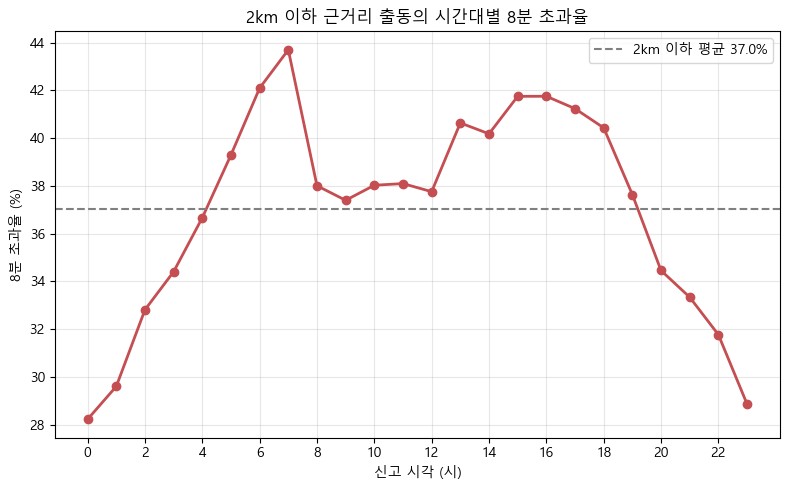

In [44]:
fig, ax = plt.subplots(figsize=(8, 5))
h = (near.groupby("hour")["late"].mean() * 100)
ax.plot(h.index, h.values, marker="o", color="#C44E52", linewidth=2)
ax.axhline(near["late"].mean()*100, color="gray", linestyle="--",
           label=f"2km 이하 평균 {near['late'].mean()*100:.1f}%")
ax.set_xlabel("신고 시각 (시)")
ax.set_ylabel("8분 초과율 (%)")
ax.set_title("2km 이하 근거리 출동의 시간대별 8분 초과율")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("eda/10_near_hour.png", dpi=150)
plt.show()

In [43]:
near = d[(d["dist_km"] <= 2) & (d["dist_km"] >= 0)]
print(f"2km 이하 {len(near):,}건 중 8분 초과: {near['late'].mean()*100:.1f}%")
print("\n시간대별:")
print((near.groupby("hour")["late"].mean() * 100).round(1))

2km 이하 393,441건 중 8분 초과: 37.0%

시간대별:
hour
0     28.2
1     29.6
2     32.8
3     34.4
4     36.7
5     39.3
6     42.1
7     43.7
8     38.0
9     37.4
10    38.0
11    38.1
12    37.8
13    40.6
14    40.2
15    41.7
16    41.8
17    41.2
18    40.4
19    37.6
20    34.5
21    33.3
22    31.8
23    28.9
Name: late, dtype: float64
